# 03 · 场景与任务生成

设置场景类型和自然语言任务；平台从资产库选择物体，生成、执行并归档场景任务。
结果统一写入四类资源索引。


In [1]:
import json
import uuid

from examples._display import (
    setup_notebook,
    show_animation,
    show_libraries,
    show_metrics,
    show_pipeline,
)

PROJECT_ROOT, OUTPUT_DIR = setup_notebook("scene_and_task_generation")

from physrealx import PhysRealX, SceneSpec, TaskSpec

px = PhysRealX.open(PROJECT_ROOT / ".physrealx")
run_key = uuid.uuid4().hex[:12]
SCENE_TYPE = "home"
ASSET_LIBRARY = PROJECT_ROOT / "examples/scene_and_task_generation/input/PartNet-Mobility"
TASK_INSTRUCTION = "使用机械臂关闭笔记本电脑屏幕"


Python,3.11.15
解释器,/home/yxp/miniconda3/envs/PhysReal-X/bin/python


## 1. 输入与资产选择


In [2]:
asset_refs = px.assets.select_partnet_mobility(
    ASSET_LIBRARY,
    scene_type=SCENE_TYPE,
    seed=2026,
)
room_ref = px.assets.create_room_shell(
    resource_id="environment.home-room",
    width_m=3.6,
    depth_m=3.6,
    height_m=2.4,
)
robot_ref = px.assets.import_mujoco_model(
    PROJECT_ROOT
    / "examples/scene_and_task_generation/input/MuJoCo-Menagerie/franka_emika_panda/panda.xml",
    resource_id="robot.franka-emika-panda",
    version="1.1.0",
    display_name="Franka Emika Panda",
    source_name="MuJoCo Menagerie/franka_emika_panda",
    source_revision="8161bba264d7fa7c99ca301e91e7fb44737676ad",
    license_name="Apache-2.0",
)
show_pipeline(
    {
        "用户输入": f"{SCENE_TYPE} · {TASK_INSTRUCTION}",
        "资产选择": f"PartNet-Mobility · {len(asset_refs)} 个物体",
        "场景生成": "布局与碰撞约束",
        "任务生成": "语言绑定与关节约束",
        "执行归档": "MuJoCo 轨迹与样本",
    }
)
show_metrics(
    {
        "场景类型": SCENE_TYPE,
        "平台选中资产": len(asset_refs),
        "机械臂": "Franka Emika Panda",
    }
)


场景类型,home
平台选中资产,5
机械臂,Franka Emika Panda


## 2. 场景布局


In [3]:
layout_operation = px.scenes.generate(
    {
        "resource_id": f"partnet.room.{run_key}",
        "version": "1.0.0",
        "display_name": "PartNet room scene",
        "domain": "home",
        "environment": room_ref.model_dump(mode="json"),
        "objects": [
            {"name": "table", "asset": asset_refs["table"].model_dump(mode="json")},
            {
                "name": "chair_left",
                "asset": asset_refs["chair"].model_dump(mode="json"),
                "yaw_rad": 1.5707963267948966,
            },
            {
                "name": "chair_right",
                "asset": asset_refs["chair"].model_dump(mode="json"),
                "yaw_rad": -1.5707963267948966,
            },
            {"name": "laptop", "asset": asset_refs["laptop"].model_dump(mode="json")},
            {"name": "lamp", "asset": asset_refs["lamp"].model_dump(mode="json")},
            {"name": "bottle", "asset": asset_refs["bottle"].model_dump(mode="json")},
        ],
        "relations": [
            {
                "subject": "chair_left",
                "relation": "left_of",
                "object": "table",
                "clearance_m": 0.15,
            },
            {
                "subject": "chair_right",
                "relation": "right_of",
                "object": "table",
                "clearance_m": 0.15,
            },
            {"subject": "laptop", "relation": "on", "object": "table", "clearance_m": 0.0},
            {"subject": "lamp", "relation": "on", "object": "table", "clearance_m": 0.0},
            {"subject": "lamp", "relation": "left_of", "object": "laptop", "clearance_m": 0.1},
            {"subject": "bottle", "relation": "on", "object": "table", "clearance_m": 0.0},
            {"subject": "bottle", "relation": "right_of", "object": "laptop", "clearance_m": 0.1},
        ],
        "xy_bounds_m": [-1.7, -1.7, 1.7, 1.7],
        "interaction_target": "laptop",
        "agent_radius_m": 0.30,
        "seed": 2026,
    },
    method="physcene_guidance",
)
composition = px.scenes.compose(
    layout_operation.output("scene_draft"), method="collision_constraints"
)
scene = SceneSpec.model_validate_json(
    px.artifacts.get_bytes(composition.output("scene_spec"))
)
show_metrics({"场景实体": len(scene.entities), "空间关系": layout_operation.metrics["relations"]})


场景实体,7
空间关系,7


## 3. 任务生成


In [4]:
laptop = px.assets.get(asset_refs["laptop"])
joint = next(item for item in laptop.joints if item.joint_type.value == "revolute")
scene = px.scenes.place_robot_for_joint_task(
    scene,
    entity="laptop",
    joint=joint.name,
    robot=robot_ref,
    name="robot_arm",
    end_effector_link="hand",
    initial_position=0.0,
    target_position=joint.lower_limit + 0.02,
    clearance_m=0.02,
    resource_id=f"partnet.room.robot.{run_key}",
)
scene_ref = px.scenes.register(scene)
task_operation = px.tasks.compile(
    TASK_INSTRUCTION,
    scene_ref,
    method="articulated_templates",
    config={
        "resource_id": f"partnet.laptop.close.{run_key}",
        "entity": "laptop",
        "joint": joint.name,
        "target_position": joint.lower_limit + 0.02,
        "initial_fraction": (0.0 - joint.lower_limit)
        / (joint.upper_limit - joint.lower_limit),
        "tolerance": 0.1,
        "max_steps": 200,
        "robot": "robot_arm",
    },
)
task = TaskSpec.model_validate_json(
    px.artifacts.get_bytes(task_operation.output("task_spec"))
)
task_ref = px.tasks.register(task)
validation = px.tasks.validate(task_ref, method="joint_constraints")
print(task.instruction)
print(json.loads(px.artifacts.get_bytes(validation.output("validation_report"))))


使用机械臂关闭笔记本电脑屏幕
{'physics_execution_required': True, 'schema': 'physrealx.task-validation-report/1', 'scope': 'schema_scene_and_joint_limits', 'status': 'PASSED'}


## 4. 执行与输出


任务成功,True
最大跟踪误差,0.1897
峰值接触力 (N),135.8


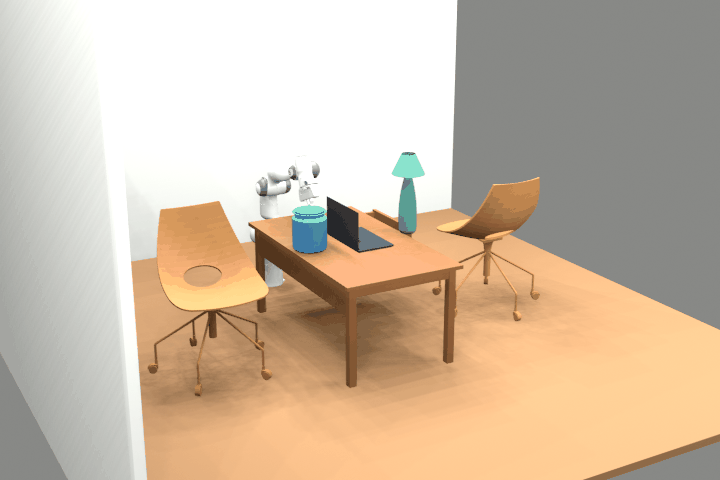

结果索引: /mnt/53dad72e-a787-4c09-961e-eff73e08888e/yxp/Desktop/pingtaidajian/PhysReal-X/examples/scene_and_task_generation/output/results.json


In [5]:
backend_config = {
    "controlled_joints": task.metadata["controlled_joints"],
    "initial_positions": task.metadata["initial_positions"],
    "effort_limits": task.metadata["effort_limits"],
    "passive_positions": task.metadata["passive_positions"],
    "position_gain": 200.0,
    "velocity_gain": 20.0,
    "timestep_seconds": 0.002,
    "substeps": 25,
}
task_instance = px.artifacts.put_json(
    {
        "schema": "physrealx.task-instance/1",
        "task": task_ref.model_dump(mode="json"),
        "backend_config": backend_config,
        "waypoints": task.metadata["waypoints"],
        "target_positions": task.metadata["target_positions"],
    }
)
trajectory_operation = px.trajectories.generate(
    task_instance,
    method="mujoco_joint_trajectory",
    config={
        "duration_seconds": 8.0,
        "settle_seconds": 1.0,
        "max_tracking_error": 0.25,
        "max_contact_force_n": 200.0,
    },
)
trajectory = trajectory_operation.output("trajectory")
planning_report_ref = trajectory_operation.output("planning_report")
planning_report = json.loads(px.artifacts.get_bytes(planning_report_ref))
show_metrics(
    {
        "任务成功": planning_report["task_success"],
        "最大跟踪误差": trajectory_operation.metrics["max_tracking_error"],
        "峰值接触力 (N)": trajectory_operation.metrics["peak_contact_force_n"],
    }
)
task_preview = px.scenes.preview_task(scene_ref, task_ref, trajectory)
show_animation(px.artifacts.get_bytes(task_preview))
successful_samples = (planning_report_ref,) if planning_report["task_success"] else ()
failed_samples = () if planning_report["task_success"] else (planning_report_ref,)
show_libraries(
    {
        "场景库": (1, scene_ref.resource_id),
        "任务脚本库": (1, task_ref.resource_id),
        "操作轨迹库": (1, trajectory.artifact_id),
        "成功/失败样本库": (
            len(successful_samples) + len(failed_samples),
            f"成功 {len(successful_samples)} · 失败 {len(failed_samples)}",
        ),
    }
)
px.artifacts.export(
    OUTPUT_DIR,
    {
        "assets": {
            name: reference.model_dump(mode="json") for name, reference in asset_refs.items()
        },
        "environment": room_ref.model_dump(mode="json"),
        "robot": robot_ref.model_dump(mode="json"),
        "scene": scene_ref.model_dump(mode="json"),
        "task": task_ref.model_dump(mode="json"),
        "task_instance": task_instance.model_dump(mode="json"),
        "trajectory": trajectory.model_dump(mode="json"),
        "planning_report": planning_report_ref.model_dump(mode="json"),
        "run": {
            "status": "successful" if planning_report["task_success"] else "failed",
            "metrics": trajectory_operation.metrics,
        },
        "libraries": {
            "scenes": [scene_ref.model_dump(mode="json")],
            "tasks": [task_ref.model_dump(mode="json")],
            "trajectories": [trajectory.model_dump(mode="json")],
            "samples": {
                "successful": [item.model_dump(mode="json") for item in successful_samples],
                "failed": [item.model_dump(mode="json") for item in failed_samples],
            },
        },
        "layout_method": "physcene_guidance",
        "execution_method": "mujoco_joint_trajectory",
    },
    files={"task-preview.gif": task_preview},
)
print("结果索引:", OUTPUT_DIR / "results.json")
